First Five Rows:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

Statistical Summary:
       SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count     150.000000    150.000000     150.000000    150.000000
mean        5.843333      3.054000       3.758667      1.198667
std         0.828066      0.433594       1.764420      0.763161
min         4.300000      2.000000       1.000000      0.100000
25%         5.100000      2.800000       1.600000      0.300000
50%         5.800000      3.000000       4.350000      1.300000
75%         6.400000      3.300000       5.100000      1.800000
max        

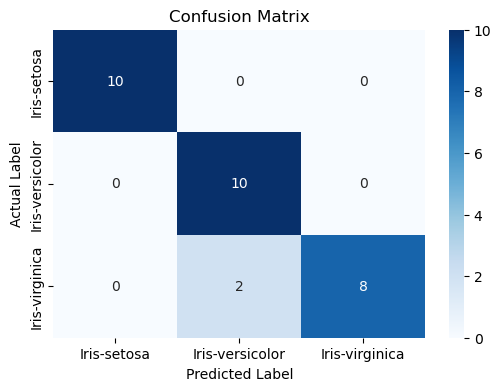


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30


Error Rate for Different K Values:
K = 1, Error Rate = 0.0333
K = 2, Error Rate = 0.0667
K = 3, Error Rate = 0.0667
K = 4, Error Rate = 0.0667
K = 5, Error Rate = 0.0667
K = 6, Error Rate = 0.0667
K = 7, Error Rate = 0.0333
K = 8, Error Rate = 0.0667
K = 9, Error Rate = 0.0333
K = 10, Error Rate = 0.0333
K = 11, Error Rate = 0.0333
K = 12, Error Rate = 0.0333
K = 13, Error Rate = 0.0333
K = 14, Error Rate = 0.0667
K = 15, Error Rate = 0.0333
K = 16, Error Rate = 0.0333
K = 17, Error Rate = 0.0333
K = 18, Error Rate = 0.0333
K = 19, Error Rate = 0.0333
K = 20, Error R

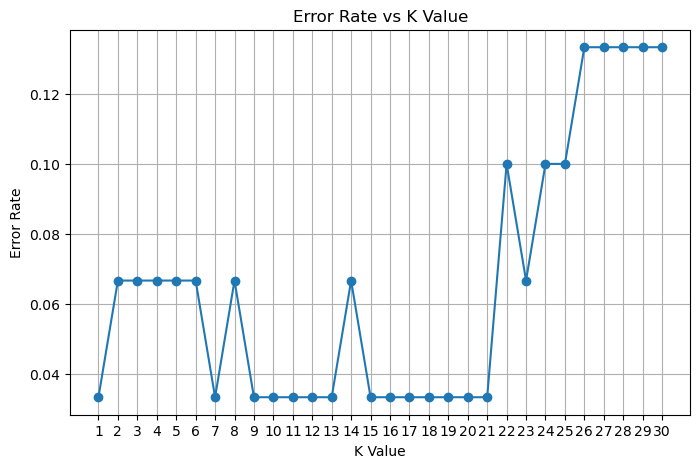


Minimum Error Rate: 0.03333333333333333
K values with minimum error: [1, 7, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21]
Best K Value: 7


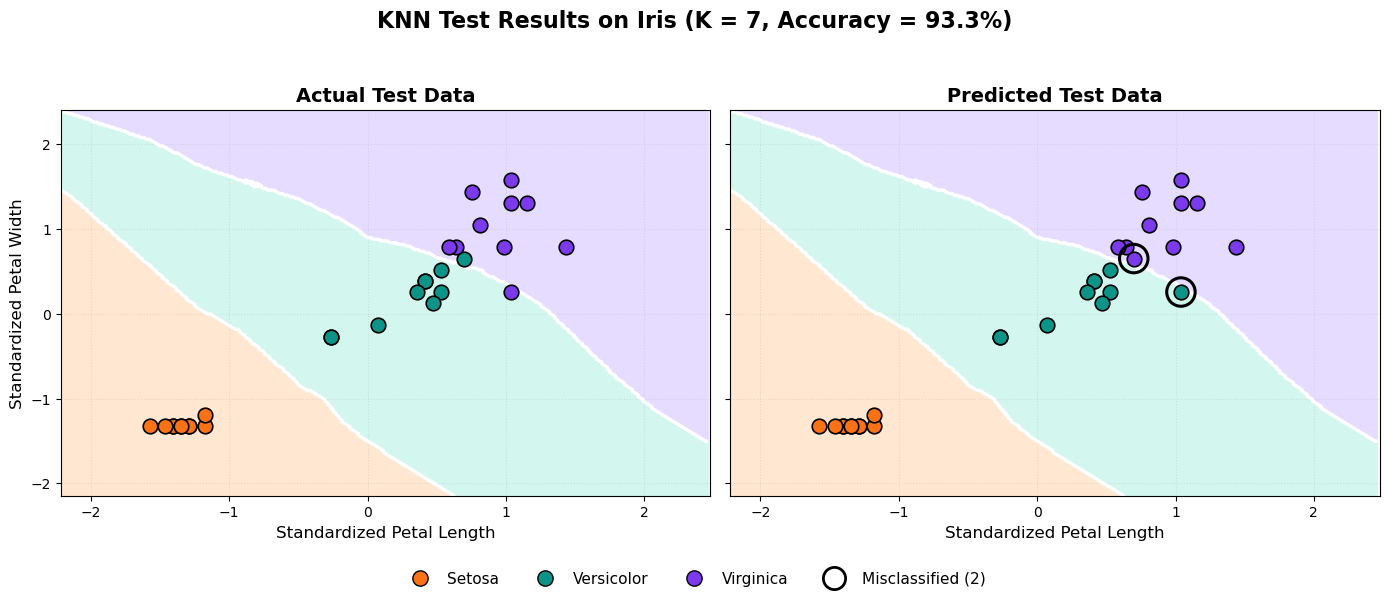

In [5]:
# PRACTICAL NO. 9: KNN ON IRIS DATASET

# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


# Q1: Perform EDA using head(), describe(), and groupby()

df = pd.read_csv("C:/Users/Ajsha/Downloads/archive (2)/Iris.csv")

df = df.drop(columns=["Id"], errors="ignore")

print("First Five Rows:")
print(df.head())

print("\nStatistical Summary:")
print(df.describe())

print("\nMean of Features by Species:")
print(df.groupby("Species").mean(numeric_only=True))

# Interpretation:
# head() displays the first five rows.
# describe() displays the statistical summary.
# groupby() calculates the mean of features for each species.


# Prepare Features and Target

X = df.drop(columns=["Species"])
y = df["Species"]


# Q2: Perform Feature Scaling

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Interpretation:
# The dataset is divided into 80% training and 20% testing data.
# StandardScaler standardizes the features for KNN classification.


# Q3: Train the KNN Model on the Training Set

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("\nPredicted Values:")
print(y_pred)

# Interpretation:
# The KNN model is trained with K = 5 and predicts
# the species of observations in the test dataset.


# Q4: Make the Confusion Matrix and Calculate Accuracy Score
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

# Q5: Generate the Classification Report

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=sorted(y.unique())
))

# Interpretation:
# Precision measures the correctness of positive predictions.
# Recall measures how many actual class observations are identified.
# F1-score is the harmonic mean of precision and recall.
# Support shows the number of actual observations in each class.


# Q6: Compare Error Rate for Different K Values

error = []

for k in range(1, 31):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    error.append(np.mean(prediction != y_test))

print("\nError Rate for Different K Values:")

for k, value in enumerate(error, start=1):
    print(f"K = {k}, Error Rate = {value:.4f}")

# Interpretation:
# Error rate is calculated for K values from 1 to 30.
# A lower error rate indicates fewer incorrect predictions.


# Q7: Plot Error Values Against K Values

plt.figure(figsize=(8, 5))

plt.plot(range(1, 31), error, marker="o")

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs K Value")

plt.xticks(range(1, 31))
plt.grid(True)

plt.show()

# Interpretation:
# The graph shows how the error rate changes with K.
# It helps identify K values with fewer classification errors.


# Q8: Find the Best K Value

min_err = min(error)
best_ks = [k for k, e in enumerate(error, start=1) if e == min_err]

# K = 1 overfits, so pick the smallest ODD K greater than 1 among the best values
best_k = next((k for k in best_ks if k > 1 and k % 2 == 1), best_ks[0])

print("\nMinimum Error Rate:", min_err)
print("K values with minimum error:", best_ks)
print("Best K Value:", best_k)

# Interpretation:
# Several K values have the same minimum error rate.
# K = 7 is selected as the smallest odd K greater than 1
# among the K values with minimum error.


# Q9: Visualize Test Results of KNN

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Select two features for 2D visualization
X2 = df[["PetalLengthCm", "PetalWidthCm"]]
y2 = df["Species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

# Feature scaling
sc2 = StandardScaler()
X2_train = sc2.fit_transform(X2_train)
X2_test = sc2.transform(X2_test)

# Train KNN using the best K
knn2 = KNeighborsClassifier(n_neighbors=best_k)
knn2.fit(X2_train, y2_train)
y2_pred = knn2.predict(X2_test)

# Mesh grid for decision regions
x_min, x_max = X2_train[:, 0].min() - 0.7, X2_train[:, 0].max() + 0.7
y_min, y_max = X2_train[:, 1].min() - 0.7, X2_train[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))
Z = knn2.predict(np.c_[xx.ravel(), yy.ravel()])
Z = pd.Categorical(Z, categories=knn2.classes_).codes.reshape(xx.shape)

# Styling
species = list(knn2.classes_)
names = [s.replace("Iris-", "").title() for s in species]
region_colors = ["#FFE5CC", "#CFF5EE", "#E4D9FF"]   # light background
point_colors = ["#F97316", "#0D9488", "#7C3AED"]     # strong points
wrong = (y2_pred != y2_test.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
fig.patch.set_facecolor("white")

for ax, labels, title in [(axes[0], y2_test.values, "Actual Test Data"),
                          (axes[1], y2_pred, "Predicted Test Data")]:
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5],
                colors=region_colors, alpha=0.9)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors="white",
               linewidths=2.5, linestyles="-")
    for i, sp in enumerate(species):
        m = labels == sp
        ax.scatter(X2_test[m, 0], X2_test[m, 1], c=point_colors[i],
                   marker="o", s=110, edgecolor="black", linewidth=1.2, zorder=3)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Standardized Petal Length", fontsize=12)
    ax.grid(True, alpha=0.3, linestyle=":")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

axes[0].set_ylabel("Standardized Petal Width", fontsize=12)

# Ring the misclassified points on the predicted panel
axes[1].scatter(X2_test[wrong, 0], X2_test[wrong, 1], s=420,
                facecolors="none", edgecolors="black", linewidths=2.2, zorder=4)

# Shared legend
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=point_colors[i],
                  markeredgecolor="black", markersize=11, label=names[i])
           for i in range(len(species))]
handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="none",
                      markeredgecolor="black", markersize=16, markeredgewidth=2,
                      label=f"Misclassified ({wrong.sum()})"))
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=11, frameon=False)

acc = accuracy_score(y2_test, y2_pred) * 100
fig.suptitle(f"KNN Test Results on Iris (K = {best_k}, Accuracy = {acc:.1f}%)",
             fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0.07, 1, 0.94])
plt.show()

# Interpretation:
# Background colours show the decision regions learned by KNN.
# The left plot shows actual test classes, the right plot shows predicted classes.
# Circled points on the right plot are misclassified test observations.